### Interpolation

In [48]:
import numpy as np
import matplotlib.pyplot as plt

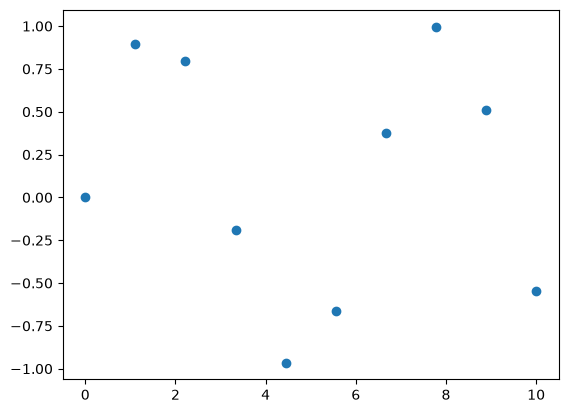

In [49]:
x = np.linspace(0,10,10)
y = np.sin(x)
plt.scatter(x,y)

In [50]:
from scipy.interpolate import interp1d

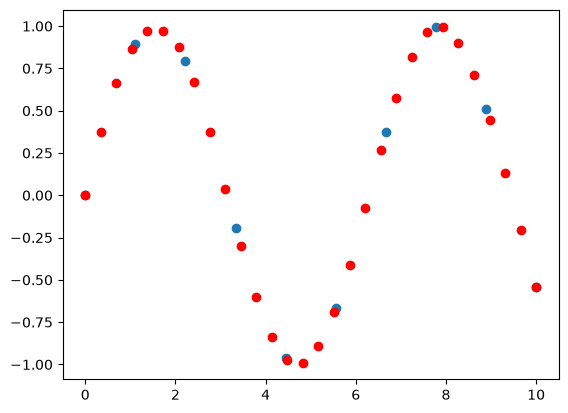

In [51]:
f = interp1d(x,y ,kind = 'cubic')

new_x =np.linspace(0,10,30)

result=f(new_x)
plt.scatter(x,y)
plt.scatter(new_x,result, c ='r')

### Optimisation <br>
 une « optimisation » avec le module scipy.optimize consiste à utiliser des algorithmes numériques pour trouver les meilleures valeurs (minimum ou maximum) d'une fonction mathématique, souvent appelée fonction objectif. C'est l'outil de référence pour résoudre des problèmes d'optimisation complexes lorsque la solution analytique (par calcul de dérivées) n'est pas possible ou trop difficile à obtenir 

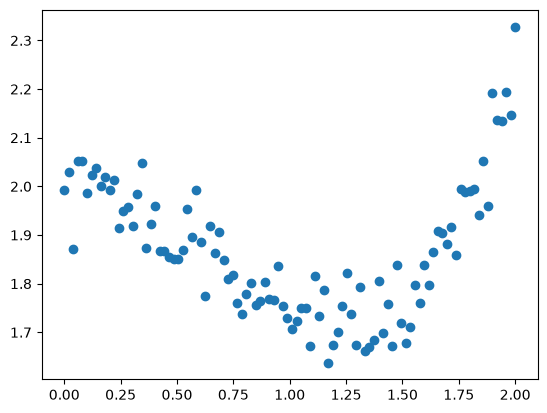

In [52]:
x = np.linspace(0,2,100)
y = 1/3*x**3-3/5* x**2 + 2 + np.random.randn(x.shape[0])/20

plt.scatter(x,y)

curve_fit est la fonction de SciPy dédiée à l'ajustement de courbe (curve fitting). Son rôle est de trouver les paramètres d'un modèle mathématique qui correspondent le mieux à un ensemble de données expérimentales, en utilisant la méthode des moindres carrés non linéaires .

In [53]:
def f(x,a,b,c,d):
  return a*x**3+b*x**2+c*x+d

In [54]:
from scipy import optimize


In [55]:
params ,params_cov = optimize.curve_fit(f,x,y)

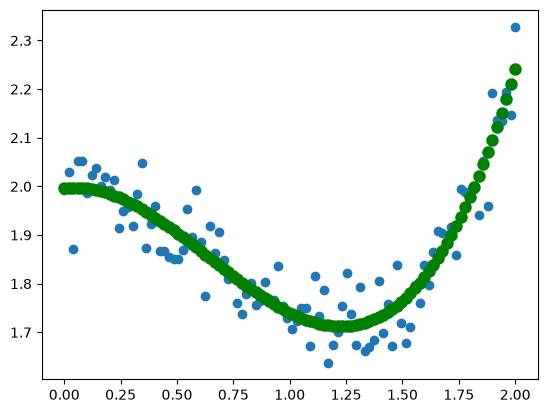

In [56]:
plt.scatter(x,y)
plt.scatter(x,f(x,params[0],params[1],params[2],params[3]),c = 'g',lw =3)

### Minimisation 

In [57]:
def f(x):
  return x**2+15*np.sin(x)

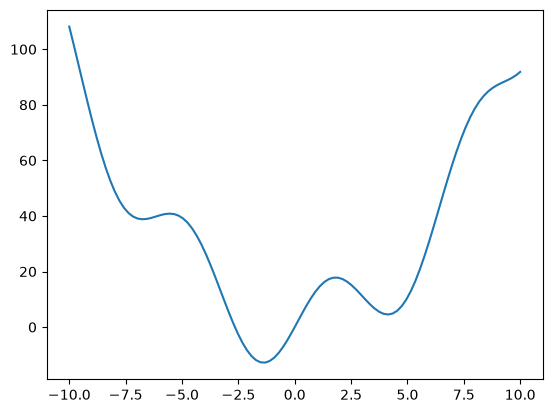

In [58]:
x = np.linspace(-10,10,100)
plt.plot(x,f(x))

In [59]:
# la fonction minimize
x0 = -5
optimize.minimize(f,x0=x0)


  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: -12.823616887804443
        x: [-1.385e+00]
      nit: 4
      jac: [ 3.576e-06]
 hess_inv: [[ 5.979e-02]]
     nfev: 18
     njev: 9

pour récupérer le resultat on procèder comme suite


In [60]:
resl = optimize.minimize(f,x0=x0).x


On peux écrire le code en bas pour afficher directement le résultat sur une graphe

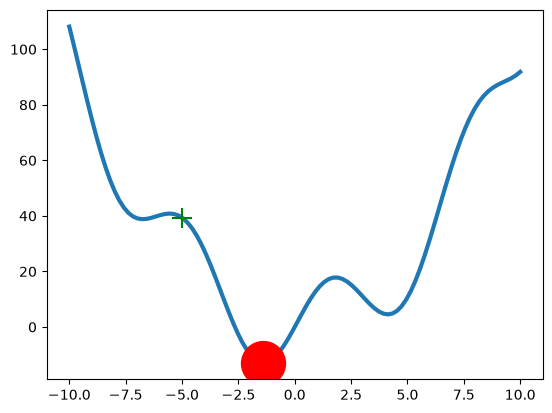

In [61]:
plt.plot(x,f(x),lw = 3,zorder=1)
plt.scatter(resl,f(resl),s =1000, c ='r',zorder = 1)
plt.scatter(x0,f(x0),s = 200,marker = '+',c = 'g',zorder =1)
plt.show()

La minimisation d'une fonction à deux variables (\(f(x, y)\) représentée en 3D avec l'altitude \(z = f(x, y)\)) consiste à trouver le point \((x, y)\) pour lequel la valeur de \(z\) est la plus basse possible.

In [62]:
def f(x) :
 	return np.sin(x[0])+np.cos(x[0]+x[1])*np.cos(x[0])

ValueError: 'x0' must only have one dimension.

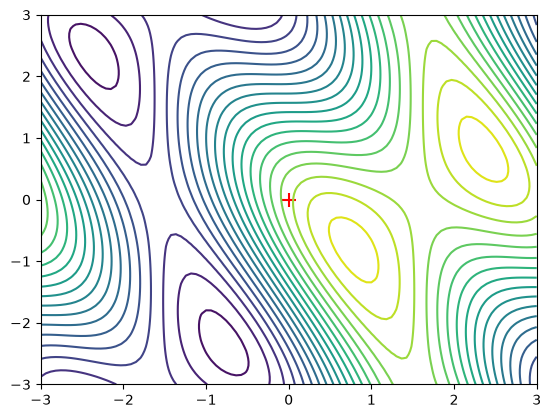

In [63]:
x = np.linspace(-3,3,100)
y = np.linspace(-3,3,100)
x,y = np.meshgrid(x,y)
 
plt.contour(x,y,f(np.array([x,y])),20)
x0 = np.zeros((2,1))
#x0 = np.array([0.0, 0.0])
plt.scatter(x0[0],x0[1],marker = '+', c ='r',s = 100)


result = optimize.minimize(f,x0=x0).x
plt.scatter(result[0],result[1], c = 'g', s =100)
print(result)


**Traitement de signale**

# 1. Introduction au traitement du signal

Le **traitement du signal** regroupe l’ensemble des méthodes permettant d’analyser, de transformer et d’extraire de l’information à partir de signaux.

Un signal est une grandeur physique qui varie dans le temps ou dans l’espace.

### Exemples de signaux
- Tension électrique provenant d’un capteur.
- Son (voix, musique).
- Courant électrique.
- Vibrations mécaniques.
- Électrocardiogramme (ECG).
- Signal radio.

---

# 2. Types de signaux

Les signaux peuvent être classés selon plusieurs critères.

## 2.1. Selon leur nature

- **Signal analogique :** continu en temps et en amplitude.
- **Signal numérique :** obtenu par échantillonnage et quantification d'un signal analogique.

## 2.2. Selon leur comportement

- **Signal déterministe :** signal dont l'évolution est prévisible et définie par une expression mathématique.
- **Signal aléatoire :** signal dont l'évolution est imprévisible, comme le bruit ou la parole.

## 2.3. Selon leur dimension

- **Signal 1D (unidimensionnel) :** signal qui varie selon une seule dimension, généralement le temps. Exemple : un signal sonore.
- **Signal 2D (bidimensionnel) :** signal qui varie selon deux dimensions. Exemple : une image.
- **Signal 3D (tridimensionnel) :** signal qui varie selon trois dimensions ou qui évolue dans le temps. Exemple : une vidéo.

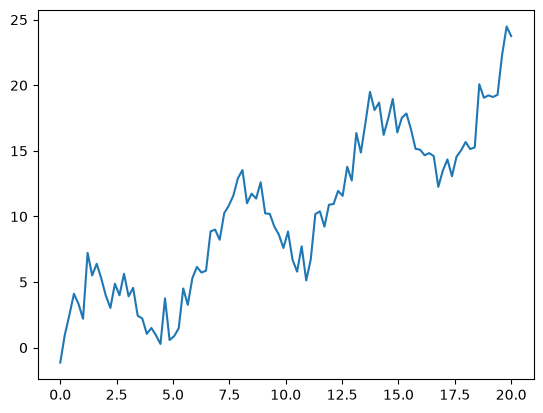

In [65]:

x = np.linspace(0,20,100)
y = x +4*np.sin(x) +np.random.randn(x.shape[0])
plt.plot(x,y)

Le module detrend n'est pas un module indépendant, mais une fonction spécifique du sous-module scipy.signal (nommée scipy.signal.detrend).
Elle sert à supprimer la tendance linéaire ou constante d'un signal ou d'une série de données.

À quoi ça sert ?

Lorsque l'on analyse des données (comme un signal audio, des données sismiques ou une série temporelle financière), le signal comporte souvent une dérive globale (une pente qui monte ou qui descend) ou un décalage constant. Cette tendance peut fausser les analyses futures, notamment le calcul de la Transformée de Fourier (FFT). detrend permet de "remettre le signal à plat" autour de zéro.

In [66]:
from scipy import signal 


In [67]:
new_y = signal.detrend(y)

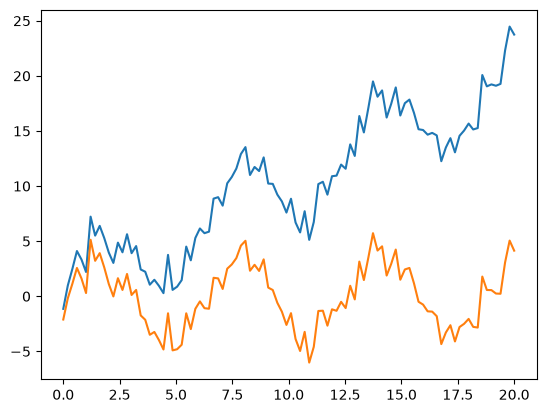

In [68]:
plt.plot(x,y)
plt.plot(x,new_y)

La transformée de Fourier est un outil mathématique qui permet de décomposer une fonction ou un signal variant au cours du temps (ou de l'espace) en ses fréquences fondamentales constitutives.

Principe et définition

• Domaine temporel vs. fréquentiel : Elle convertit un signal du domaine temporel f(t) vers le domaine fréquentiel f̂(ξ).
</br>
• Formule générale : Pour une fonction f(t), la transformée de Fourier f̂(ξ) est définie par :

$${f}(\xi )=\int _{-\infty }^{\infty }f(t)e^{-i\xi t}dt$$
Avec :

$f(t)$ : le signal dans le domaine temporel.

$\hat{f}(\xi)$ : la transformée de Fourier du signal.

$t$ : la variable temporelle.

$\xi$ : la pulsation (fréquence angulaire).

$i$ : l'unité imaginaire ($i^2=-1$).

$e^{-i\xi t}$ : l'exponentielle complexe.

• Analogie simple : C’est comme un filtre ou un prisme qui décompose un son complexe (un accord de musique) ou un smoothie (mélange de fruits) en ses ingrédients de base (les notes ou fréquences individuelles).

**La composition de signal**

Pour illustrer la composition de trois signaux dans le domaine fréquentiel (repère de fréquence), imaginez que nous combinons deux ondes sinusoïdales simples. Lorsque ces signaux se superposent, leurs fréquences respectives apparaissent sous la forme de la figure du milieu 

![Mon Schémas](pictures/comp.png)

En traitement du signal, utiliser scipy.signal.detrend juste avant d'appliquer une Transformée de Fourier Rapide (FFT) est une excellente pratique.
Lorsque l'on parle "d'assemblage", l'ordre logique et crucial des opérations consiste à nettoyer le signal (detrend) puis à l'analyser (FFT). Si vous ne supprimez pas la tendance d'abord, le résultat de votre FFT sera fortement faussé.

**Exemple de figure d'assemblage**

Transfomation de fourier
analyse les <span style="color: yellow;">fréquences </span>présentes dans un signal
<span style="color: red;">périodique.</span>


En résultat:**Un spectre**

![Mon Schéma](pictures/ass.png)

**EXEMPLE DE SIGNALE**

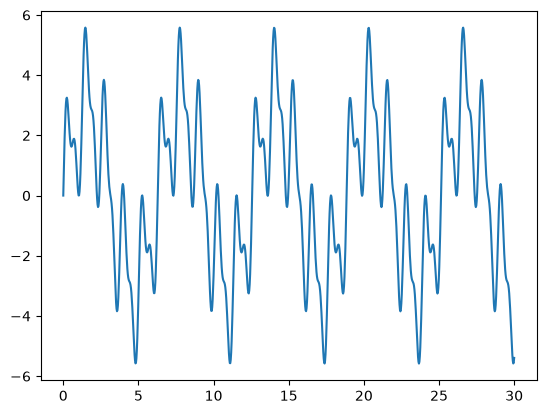

In [69]:
x =np.linspace(0,30,1000)
y =3*np.sin(x)+2*np.sin(5*x)+np.sin(10*x)
plt.plot(x,y)

In [70]:
from scipy import fftpack

/home/mariam/Documents/diarrab/mon_venv/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/mariam/Documents/diarrab/mon_venv/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


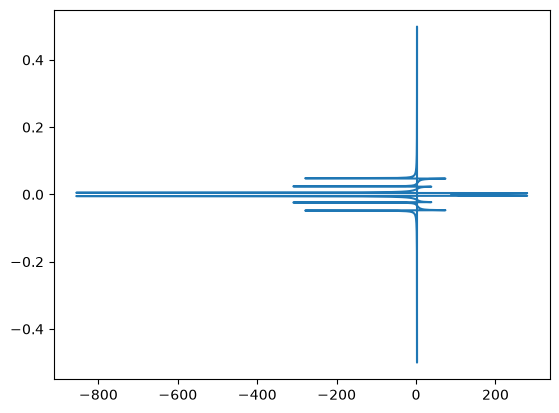

In [75]:
fourier = fftpack.fft(y)
frequence = fftpack.fftfreq(y.size)
plt.plot(fourier,frequence)

sauf avec ça on a pris en compte qu'il peut avoir des signal négative et positive

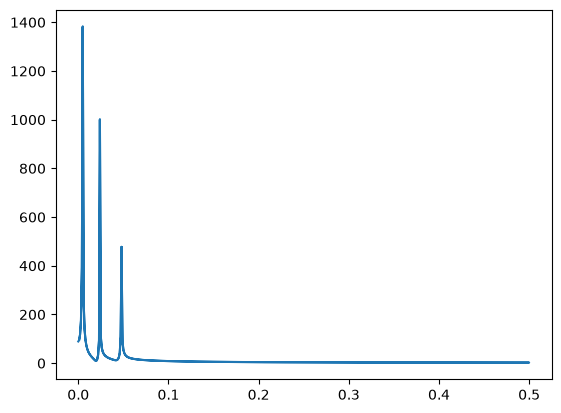

In [ ]:
fourier = fftpack.fft(y)
# on vas utiliser la fonction vleur absolue 
pos_abs=np.abs(fourier)
# la variable pos_abs pour positive absolue
frequence = fftpack.fftfreq(y.size)
#sans oublier de faire la modification suivante
plt.plot(np.abs(frequence),pos_abs)

**UNE APPLICATION**:<span style ='color :red;'>DE FILTRAGE DE SIGNALE</span>

On vas utiliser le même code pour faire le filtrage d'image

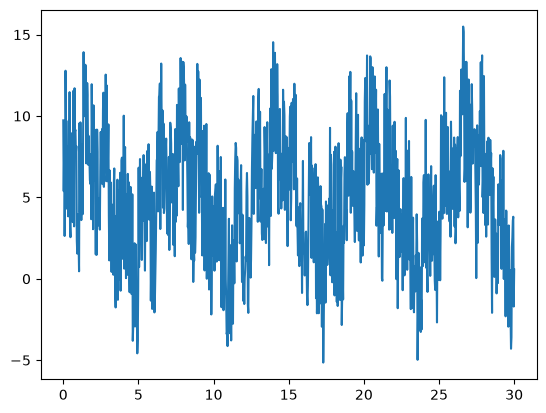

In [82]:
x =np.linspace(0,30,1000)
y =3*np.sin(x)+2*np.sin(5*x)+np.sin(10*x)+np.random.random(x.shape[0])*10
plt.plot(x,y)

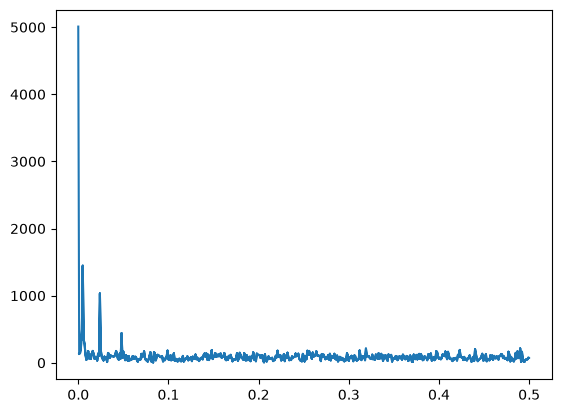

In [83]:
fourier = fftpack.fft(y)
# on vas utiliser la fonction vleur absolue 
pos_abs=np.abs(fourier)
# la variable pos_abs pour positive absolue
frequence = fftpack.fftfreq(y.size)
#sans oublier de faire la modification suivante
plt.plot(np.abs(frequence),pos_abs)

In [84]:
# pour simplifie le signale si dessous et d'efface certain signal on procède comme suite

fourier[pos_abs<400] =0 

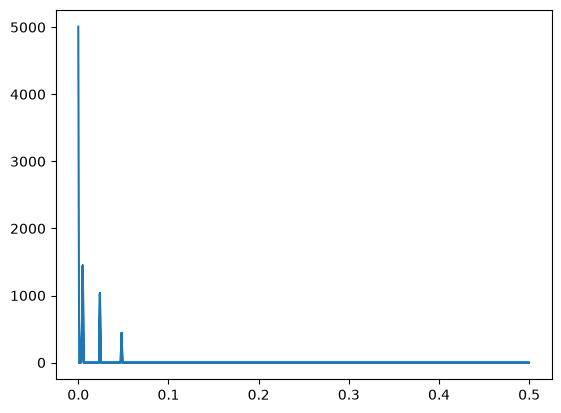

In [85]:
plt.plot(np.abs(frequence),np.abs(fourier))

On vas appliqué la transformation de fourier inverse

La Transformation de Fourier Inverse (IFFT) est l'opération exactement mathématiquement opposée à la FFT : elle permet de repasser du domaine des fréquences au domaine temporel.

Si la FFT prend un signal temporel pour en extraire ses notes de musique (les fréquences), l'IFFT prend ces notes (amplitudes et phases) pour reconstruire le signal d'origine dans le temps.

In [86]:
#on vas créer une variable filtered_signal pour appliqué la ifft
filtered_signal =fftpack.ifft(fourier)


/home/mariam/Documents/diarrab/mon_venv/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/mariam/Documents/diarrab/mon_venv/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


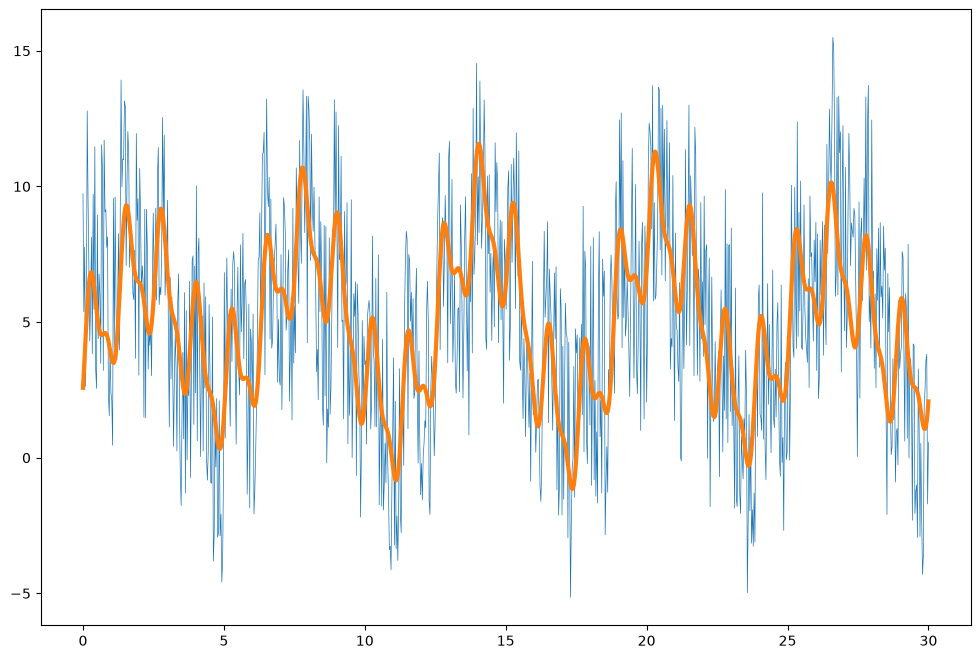

In [87]:
#Avec un peu de matplotlib 
plt.figure(figsize =(12,8))

plt.plot(x,y,lw = 0.5)
plt.plot(x,filtered_signal,lw=3)
plt.show()

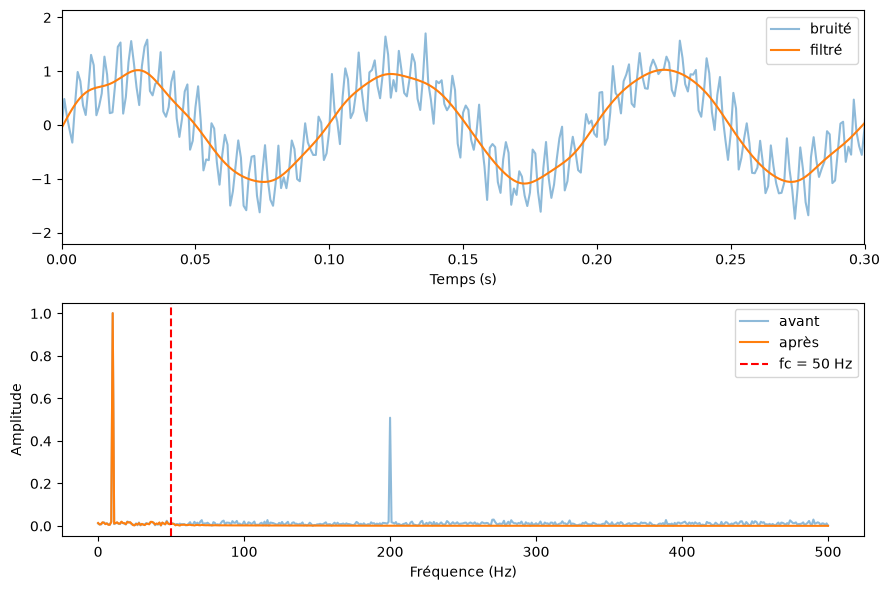

In [ ]:
import numpy as np
import scipy.signal as sg
import matplotlib.pyplot as plt

fs = 1000                       # fréquence d'échantillonnage (Hz)
fc = 50                         # fréquence de coupure (Hz)
t = np.arange(0, 1, 1/fs)

# Signal de test : 10 Hz utile + 200 Hz parasite + bruit
x = np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*200*t) + 0.2*np.random.randn(len(t))

# Filtre passe-bas Butterworth d'ordre 4
b, a = sg.butter(4, fc/(fs/2), btype='low')
y = sg.filtfilt(b, a, x)        # filtrage à phase nulle

# Spectres (amplitude)
freqs = np.fft.rfftfreq(len(x), 1/fs)
X = np.abs(np.fft.rfft(x)) / len(x) * 2
Y = np.abs(np.fft.rfft(y)) / len(y) * 2

fig, ax = plt.subplots(2, 1, figsize=(9, 6))
ax[0].plot(t, x, alpha=0.5, label="bruité")
ax[0].plot(t, y, label="filtré")
ax[0].set(xlabel="Temps (s)", xlim=(0, 0.3)); ax[0].legend()
ax[1].plot(freqs, X, alpha=0.5, label="avant")
ax[1].plot(freqs, Y, label="après")
ax[1].axvline(fc, color='r', ls='--', label=f"fc = {fc} Hz")
ax[1].set(xlabel="Fréquence (Hz)", ylabel="Amplitude"); ax[1].legend()
plt.tight_layout(); plt.show()

**LE TRAITEMENT D'IMAGE**